<a href="https://colab.research.google.com/github/chandrahzzz/EDA-COURSE/blob/main/pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

23BDS0308

In [1]:
pkgs <- c("ggplot2", "dplyr", "tidyr", "corrplot")
new  <- pkgs[!pkgs %in% installed.packages()[, "Package"]]
if (length(new)) install.packages(new, quiet = TRUE)

library(ggplot2); library(dplyr); library(tidyr); library(corrplot)
options(repr.plot.width = 12, repr.plot.height = 7, scipen = 999)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


corrplot 0.95 loaded



LOADING THE DATASET

In [2]:
url <- "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/catholic.csv"
df  <- read.csv(url, na.strings = c("", "NA"))   # blank cells in hsgrad -> NA
dim(df)
head(df, 10)

[1] 7430   14

,rownames,id,read12,math12,female,asian,hispan,black,motheduc,fatheduc,lfaminc,hsgrad,cathhs,parcath
,<int>,<int>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>
1,1,124902,61.41,49.77,0,0,0,0,14,12,10.308950,1,0,1
2,2,124915,58.34,59.84,0,0,0,0,14,14,10.308950,1,0,1
3,3,124916,59.33,50.38,1,0,0,0,14,11,10.308950,1,0,1
4,4,124932,49.59,45.03,1,0,0,0,12,14,10.308950,1,0,1
5,5,124944,57.62,54.26,1,0,0,0,12,12,10.657260,1,0,1
6,6,124947,52.53,56.73,1,0,0,0,12,11,11.042920,1,0,1
7,7,124966,60.12,55.37,1,0,0,0,14,14,9.433484,1,0,1
8,8,124968,64.69,65.07,0,0,0,0,14,14,10.308950,1,0,1
9,9,124972,42.09,53.98,0,0,0,0,14,14,10.308950,1,0,1


UNDERSTANDING THE DATASET

In [3]:
str(df)
summary(df)

cat("\nMissing values per column:\n")
print(colSums(is.na(df)))

cat("\nUnique values per column:\n")
print(sapply(df, function(x) length(unique(x))))

'data.frame':	7430 obs. of  14 variables:
 $ rownames: int  1 2 3 4 5 6 7 8 9 10 ...
 $ id      : int  124902 124915 124916 124932 124944 124947 124966 124968 124972 124974 ...
 $ read12  : num  61.4 58.3 59.3 49.6 57.6 ...
 $ math12  : num  49.8 59.8 50.4 45 54.3 ...
 $ female  : int  0 0 1 1 1 1 1 0 0 0 ...
 $ asian   : int  0 0 0 0 0 0 0 0 0 0 ...
 $ hispan  : int  0 0 0 0 0 0 0 0 0 0 ...
 $ black   : int  0 0 0 0 0 0 0 0 0 0 ...
 $ motheduc: num  14 14 14 12 12 12 14 14 14 14 ...
 $ fatheduc: num  12 14 11 14 12 11 14 14 14 12 ...
 $ lfaminc : num  10.3 10.3 10.3 10.3 10.7 ...
 $ hsgrad  : int  1 1 1 1 1 1 1 1 1 1 ...
 $ cathhs  : int  0 0 0 0 0 0 0 0 0 0 ...
 $ parcath : int  1 1 1 1 1 1 1 1 1 1 ...


    rownames          id              read12          math12     
 Min.   :   1   Min.   : 124902   Min.   :29.15   Min.   :29.50  
 1st Qu.:1858   1st Qu.:2424049   1st Qu.:44.52   1st Qu.:45.02  
 Median :3716   Median :4592442   Median :53.08   Median :52.53  
 Mean   :3716   Mean   :4589838   Mean   :51.77   Mean   :52.13  
 3rd Qu.:5573   3rd Qu.:7241106   3rd Qu.:59.47   3rd Qu.:59.86  
 Max.   :7430   Max.   :7979086   Max.   :68.09   Max.   :71.37  
                                                                 
     female           asian             hispan           black        
 Min.   :0.0000   Min.   :0.00000   Min.   :0.0000   Min.   :0.00000  
 1st Qu.:0.0000   1st Qu.:0.00000   1st Qu.:0.0000   1st Qu.:0.00000  
 Median :1.0000   Median :0.00000   Median :0.0000   Median :0.00000  
 Mean   :0.5174   Mean   :0.05168   Mean   :0.1035   Mean   :0.07066  
 3rd Qu.:1.0000   3rd Qu.:0.00000   3rd Qu.:0.0000   3rd Qu.:0.00000  
 Max.   :1.0000   Max.   :1.00000   Max.   :1.


Missing values per column:
rownames       id   read12   math12   female    asian   hispan    black 
       0        0        0        0        0        0        0        0 
motheduc fatheduc  lfaminc   hsgrad   cathhs  parcath 
       0        0        0     1460        0        0 

Unique values per column:
rownames       id   read12   math12   female    asian   hispan    black 
    7430     7430     2981     3114        2        2        2        2 
motheduc fatheduc  lfaminc   hsgrad   cathhs  parcath 
       8        8       15        3        2        2 


CLEAN N CHOOSE THE PCA VARIABLES

In [4]:
df <- df %>% select(-rownames, -id)

pca_vars <- c("read12", "math12", "motheduc", "fatheduc", "lfaminc")

# Readable labels for the binary columns (used only for colouring)
df <- df %>% mutate(
  gender   = factor(female, levels = c(0, 1), labels = c("Male", "Female")),
  school   = factor(cathhs, levels = c(0, 1), labels = c("Non-Catholic HS", "Catholic HS")),
  parent   = factor(parcath, levels = c(0, 1), labels = c("Parent not Catholic", "Parent Catholic")),
  race     = case_when(asian == 1 ~ "Asian", hispan == 1 ~ "Hispanic",
                       black == 1 ~ "Black", TRUE ~ "White/Other"),
  hsgrad_f = factor(hsgrad, levels = c(0, 1), labels = c("Not grad", "Grad"))
)

df_pca <- df[complete.cases(df[, pca_vars]), ]
X      <- df_pca[, pca_vars]
cat("Rows used for PCA:", nrow(X), "\n")

Rows used for PCA: 7430 


CHECKING SCALES AND DISTRIBUTION

     read12 math12 motheduc fatheduc lfaminc
mean  51.77  52.13    13.36    13.67   10.35
sd     9.41   9.46     2.01     2.27    0.79
min   29.15  29.50     8.00     8.00    6.21
max   68.09  71.37    18.00    18.00   12.35


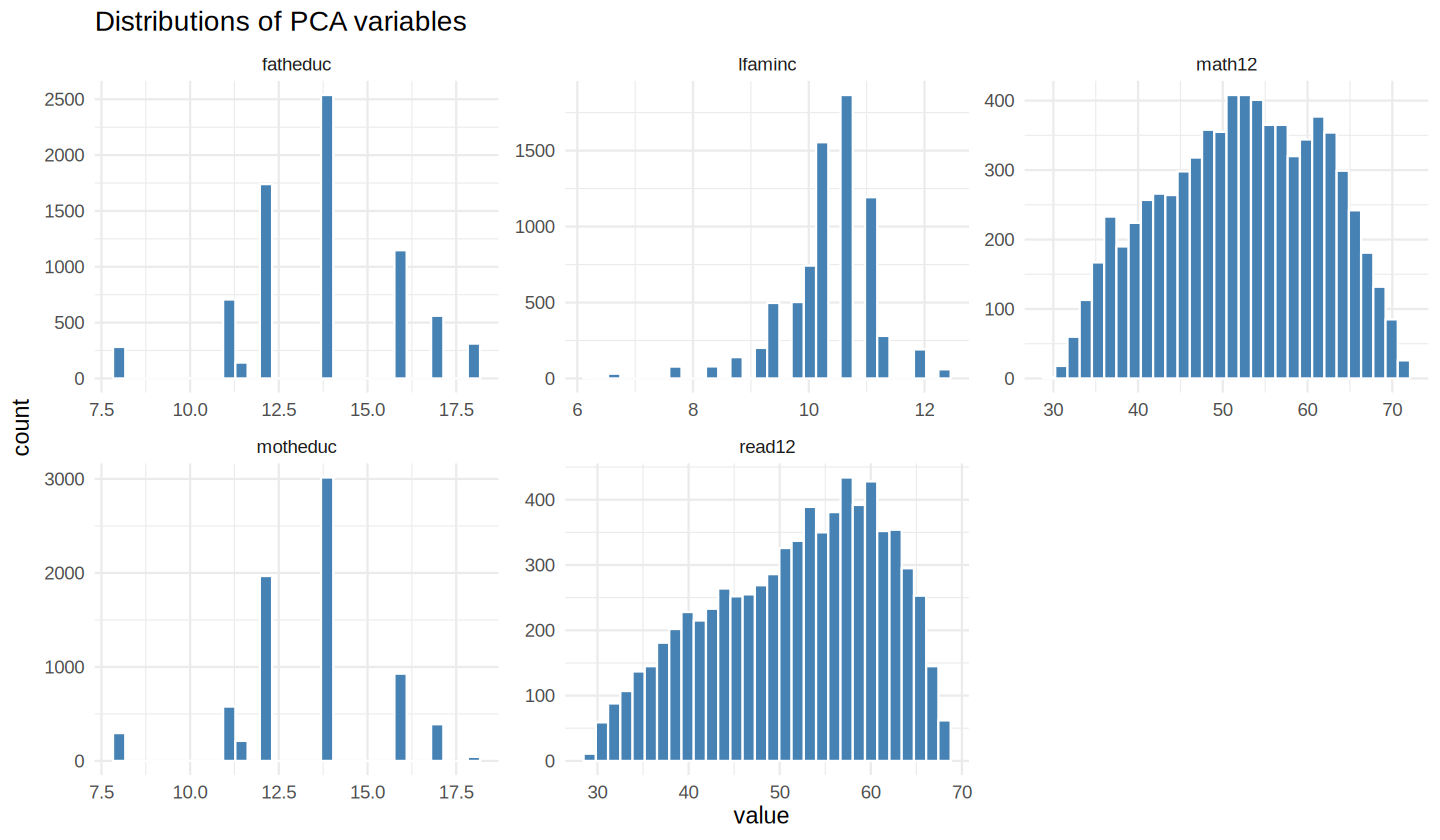

In [5]:
print(round(sapply(X, function(v) c(mean = mean(v), sd = sd(v),
                                     min = min(v), max = max(v))), 2))

X %>% pivot_longer(everything()) %>%
  ggplot(aes(value)) +
  geom_histogram(bins = 30, fill = "steelblue", colour = "white") +
  facet_wrap(~ name, scales = "free") +
  labs(title = "Distributions of PCA variables") + theme_minimal(14)

CORELATION MATRIX

         read12 math12 motheduc fatheduc lfaminc
read12    1.000  0.710    0.285    0.317   0.259
math12    0.710  1.000    0.342    0.375   0.316
motheduc  0.285  0.342    1.000    0.583   0.405
fatheduc  0.317  0.375    0.583    1.000   0.446
lfaminc   0.259  0.316    0.405    0.446   1.000


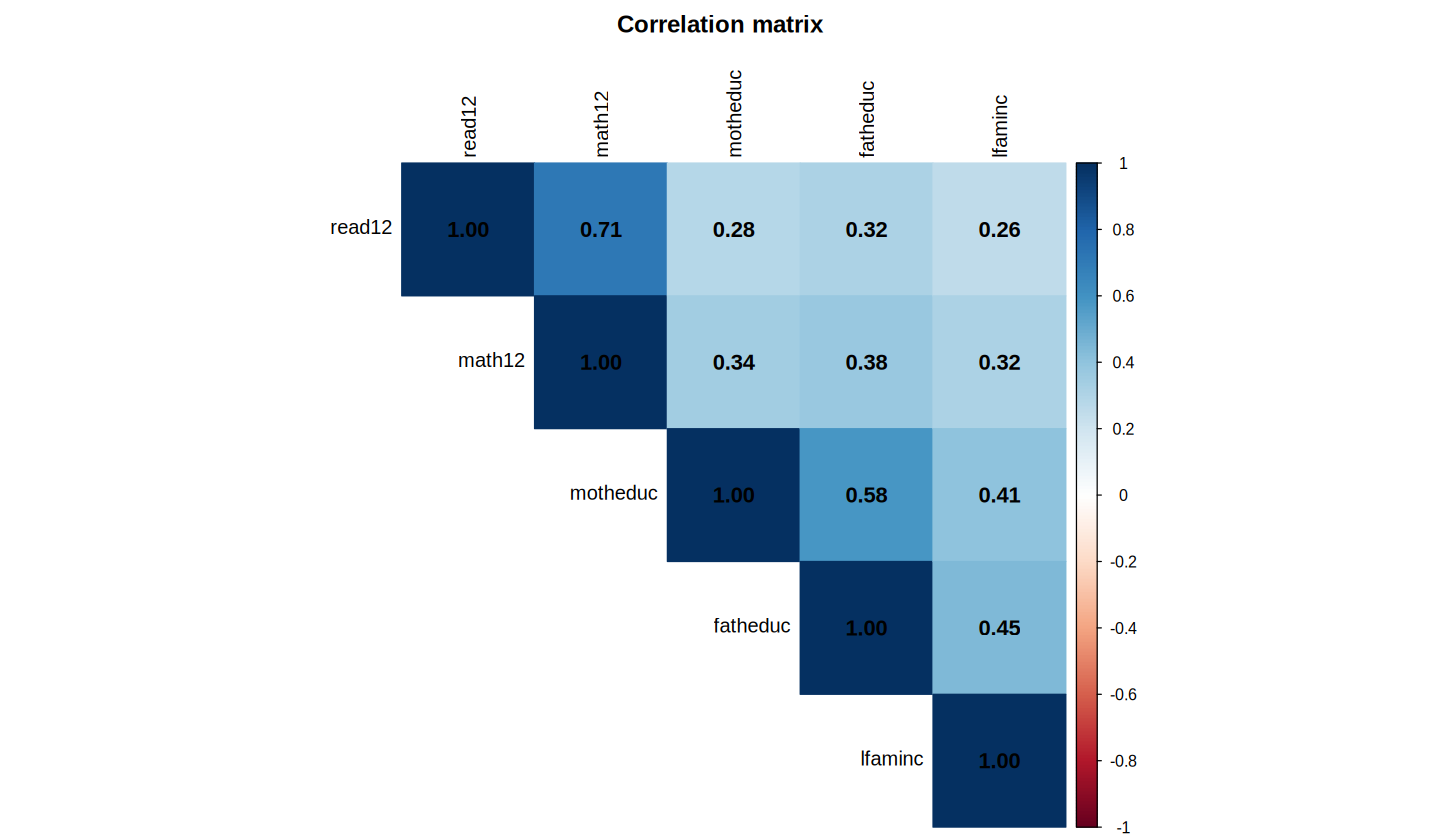

In [6]:
R <- cor(X)
print(round(R, 3))
corrplot(R, method = "color", type = "upper", addCoef.col = "black",
         tl.col = "black", number.cex = 1.1, title = "Correlation matrix",
         mar = c(0, 0, 2, 0))

SIR,NOW MY GOAL IS TO SAY IF THIS DATASET IS SUITABLE FOR PCA OR NOT

In [7]:
n <- nrow(X); p <- ncol(X)

# Bartlett's test of sphericity: H0 = correlation matrix is an identity matrix
chi2 <- -(n - 1 - (2 * p + 5) / 6) * log(det(R))
dfb  <- p * (p - 1) / 2
cat("Bartlett chi-square =", round(chi2, 2), " df =", dfb,
    " p-value =", signif(pchisq(chi2, dfb, lower.tail = FALSE), 4), "\n")

# Kaiser-Meyer-Olkin measure of sampling adequacy
Rinv <- solve(R)
P    <- -Rinv / sqrt(outer(diag(Rinv), diag(Rinv)))   # partial correlations
R0 <- R; diag(R0) <- 0; diag(P) <- 0
kmo <- sum(R0^2) / (sum(R0^2) + sum(P^2))
msa <- colSums(R0^2) / (colSums(R0^2) + colSums(P^2))
cat("Overall KMO =", round(kmo, 3), "\n"); print(round(msa, 3))

Bartlett chi-square = 11809.68  df = 10  p-value = 0 
Overall KMO = 0.704 
  read12   math12 motheduc fatheduc  lfaminc 
   0.632    0.650    0.742    0.736    0.839 


In [8]:
pca <- prcomp(X, center = TRUE, scale. = TRUE)
summary(pca)

Importance of components:
                          PC1    PC2    PC3     PC4     PC5
Standard deviation     1.6193 1.0265 0.7909 0.64272 0.53437
Proportion of Variance 0.5244 0.2107 0.1251 0.08262 0.05711
Cumulative Proportion  0.5244 0.7352 0.8603 0.94289 1.00000

EIGENVALUES AND VARIANCE

In [9]:
eig <- data.frame(
  PC         = paste0("PC", 1:p),
  Eigenvalue = pca$sdev^2,
  Variance   = 100 * pca$sdev^2 / sum(pca$sdev^2)
) %>% mutate(Cumulative = cumsum(Variance))
print(eig %>% mutate(across(where(is.numeric), ~ round(.x, 3))))

   PC Eigenvalue Variance Cumulative
1 PC1      2.622   52.441     52.441
2 PC2      1.054   21.075     73.516
3 PC3      0.626   12.511     86.027
4 PC4      0.413    8.262     94.289
5 PC5      0.286    5.711    100.000


How many components to keep

In [10]:
k_kaiser <- sum(eig$Eigenvalue > 1)
k_80     <- which(eig$Cumulative >= 80)[1]
cat("Kaiser rule (eigenvalue > 1):", k_kaiser, "components\n")
cat("80% cumulative variance rule:", k_80, "components\n")
k <- max(2, k_kaiser)   # keep at least 2 so we can plot

Kaiser rule (eigenvalue > 1): 2 components
80% cumulative variance rule: 3 components


In [11]:
loadings <- pca$rotation
print(round(loadings, 3))

# Correlation of each variable with each PC (easier to interpret)
var_cor <- sweep(loadings, 2, pca$sdev, `*`)
print(round(var_cor[, 1:k], 3))

# Contribution (%) of each variable to each PC
contrib <- 100 * loadings^2
print(round(contrib[, 1:k], 1))

            PC1    PC2    PC3    PC4    PC5
read12   -0.442 -0.580 -0.003 -0.021 -0.684
math12   -0.474 -0.496  0.011 -0.019  0.727
motheduc -0.446  0.400 -0.459 -0.656 -0.029
fatheduc -0.467  0.367 -0.293  0.748 -0.031
lfaminc  -0.403  0.351  0.839 -0.097 -0.039
            PC1    PC2
read12   -0.715 -0.596
math12   -0.768 -0.509
motheduc -0.723  0.410
fatheduc -0.757  0.377
lfaminc  -0.653  0.360
          PC1  PC2
read12   19.5 33.7
math12   22.5 24.6
motheduc 19.9 16.0
fatheduc 21.8 13.5
lfaminc  16.2 12.3


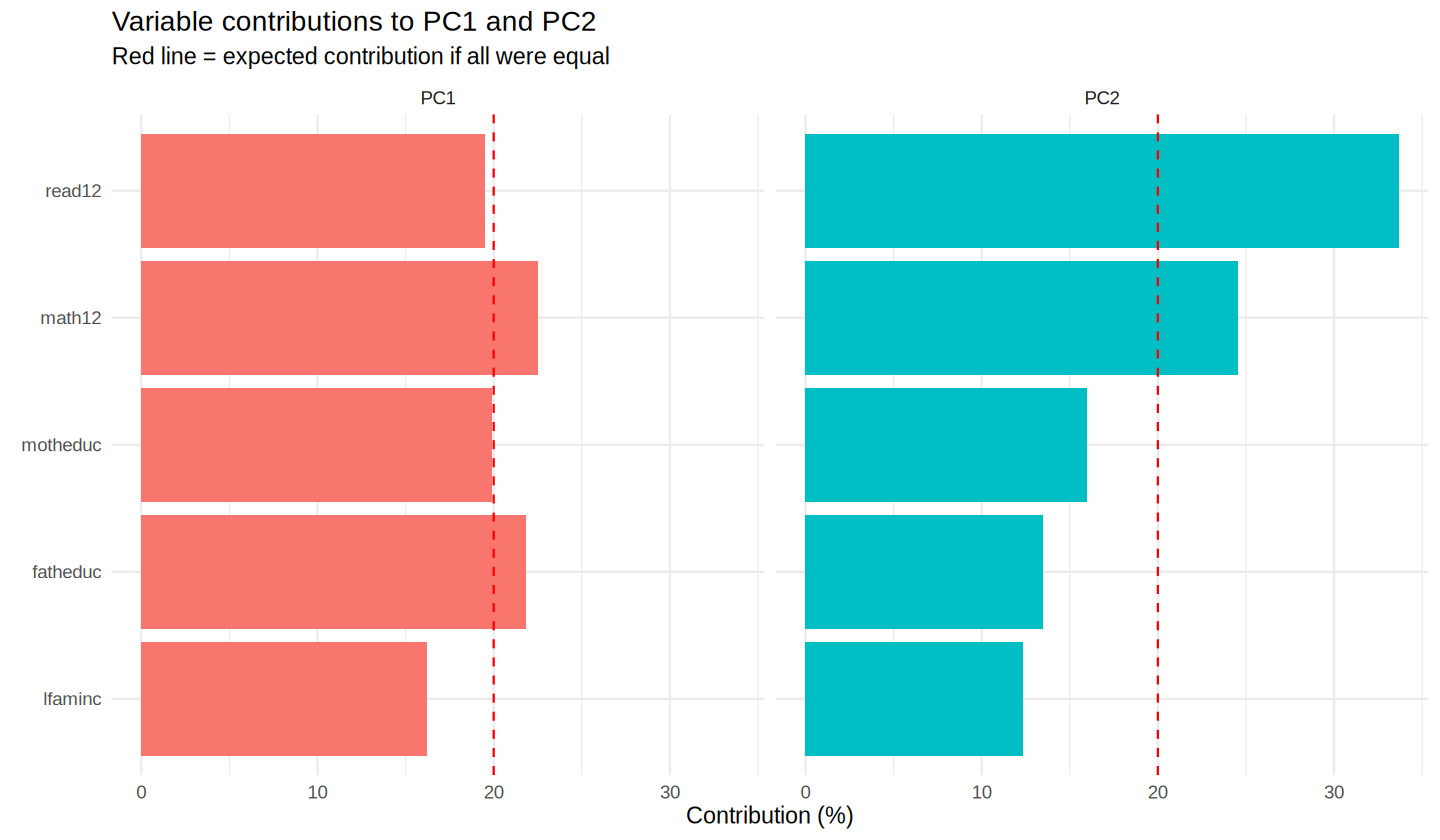

In [12]:
as.data.frame(contrib[, 1:2]) %>%
  mutate(variable = rownames(contrib)) %>%
  pivot_longer(-variable, names_to = "PC", values_to = "contribution") %>%
  ggplot(aes(reorder(variable, contribution), contribution, fill = PC)) +
  geom_col(show.legend = FALSE) +
  geom_hline(yintercept = 100 / p, linetype = "dashed", colour = "red") +
  coord_flip() + facet_wrap(~ PC) +
  labs(title = "Variable contributions to PC1 and PC2",
       subtitle = "Red line = expected contribution if all were equal",
       x = NULL, y = "Contribution (%)") + theme_minimal(14)

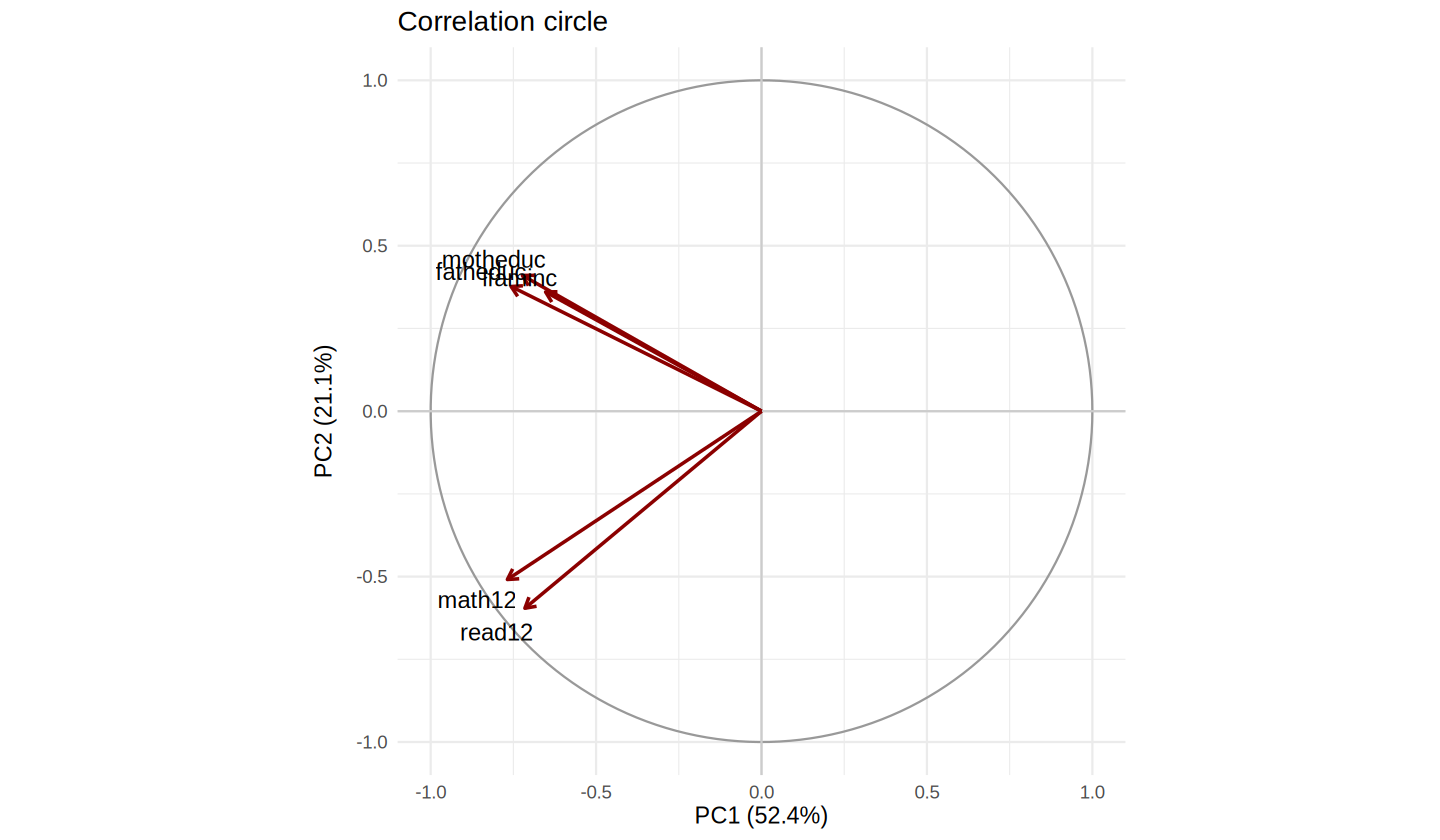

In [13]:
circle <- data.frame(x = cos(seq(0, 2 * pi, length.out = 200)),
                     y = sin(seq(0, 2 * pi, length.out = 200)))
vc <- data.frame(var = rownames(var_cor), PC1 = var_cor[, 1], PC2 = var_cor[, 2])

ggplot() +
  geom_path(data = circle, aes(x, y), colour = "grey60") +
  geom_hline(yintercept = 0, colour = "grey80") +
  geom_vline(xintercept = 0, colour = "grey80") +
  geom_segment(data = vc, aes(0, 0, xend = PC1, yend = PC2),
               arrow = arrow(length = unit(0.25, "cm")), colour = "darkred", linewidth = 1) +
  geom_text(data = vc, aes(PC1 * 1.12, PC2 * 1.12, label = var), size = 5) +
  coord_equal() +
  labs(title = "Correlation circle",
       x = sprintf("PC1 (%.1f%%)", eig$Variance[1]),
       y = sprintf("PC2 (%.1f%%)", eig$Variance[2])) + theme_minimal(14)

In [14]:
scores <- as.data.frame(pca$x[, 1:k])
df_pca <- bind_cols(df_pca, scores)
head(df_pca[, c(pca_vars, colnames(scores))])

,read12,math12,motheduc,fatheduc,lfaminc,PC1,PC2
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,61.41,49.77,14,12,10.30895,-0.1094751,-0.6330089
2,58.34,59.84,14,14,10.30895,-0.8824725,-0.6475857
3,59.33,50.38,14,11,10.30895,0.1636645,-0.6985236
4,49.59,45.03,12,14,10.30895,0.7158840,0.2695879
5,57.62,54.26,12,12,10.65726,0.1115947,-0.8791178
6,52.53,56.73,12,11,11.04292,0.2371699,-0.6860575


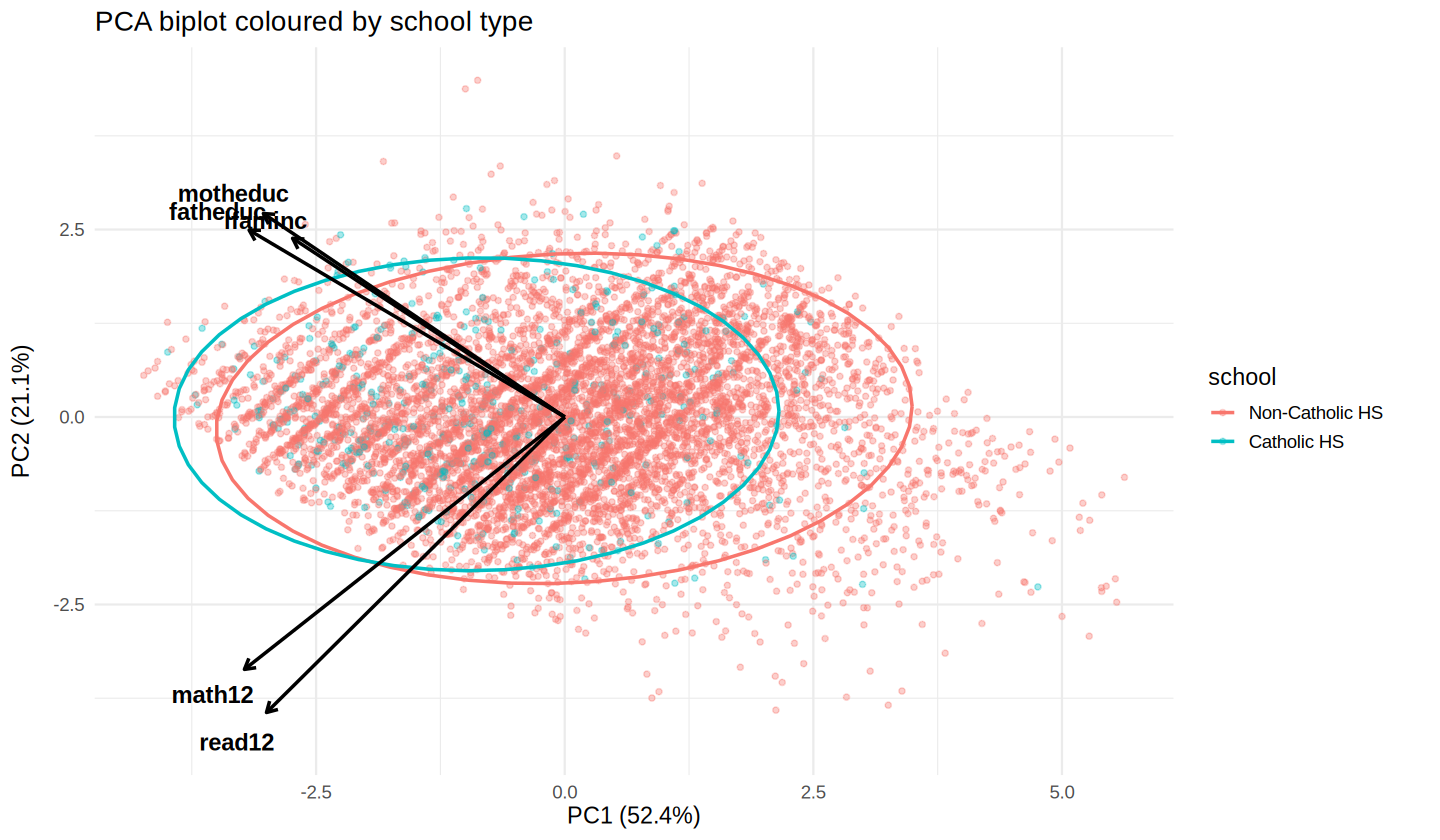

In [15]:
sc  <- max(abs(pca$x[, 1:2])) / max(abs(loadings[, 1:2])) * 0.7
arr <- data.frame(var = rownames(loadings),
                  x = loadings[, 1] * sc, y = loadings[, 2] * sc)

ggplot(df_pca, aes(PC1, PC2, colour = school)) +
  geom_point(alpha = 0.35, size = 1.3) +
  stat_ellipse(linewidth = 1) +
  geom_segment(data = arr, aes(0, 0, xend = x, yend = y), inherit.aes = FALSE,
               arrow = arrow(length = unit(0.25, "cm")), linewidth = 1) +
  geom_text(data = arr, aes(x * 1.1, y * 1.1, label = var),
            inherit.aes = FALSE, size = 5, fontface = "bold") +
  labs(title = "PCA biplot coloured by school type",
       x = sprintf("PC1 (%.1f%%)", eig$Variance[1]),
       y = sprintf("PC2 (%.1f%%)", eig$Variance[2])) + theme_minimal(14)

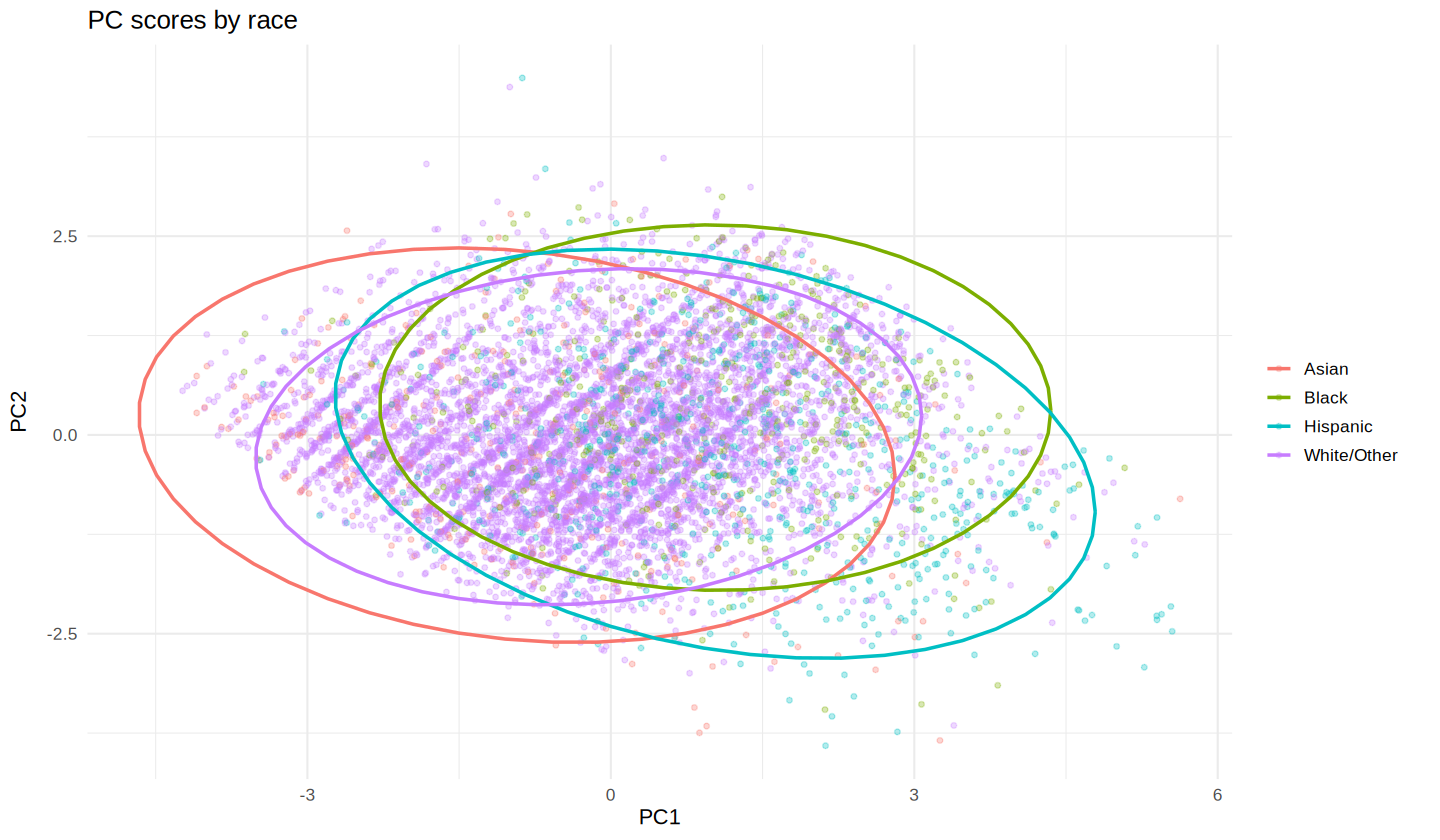

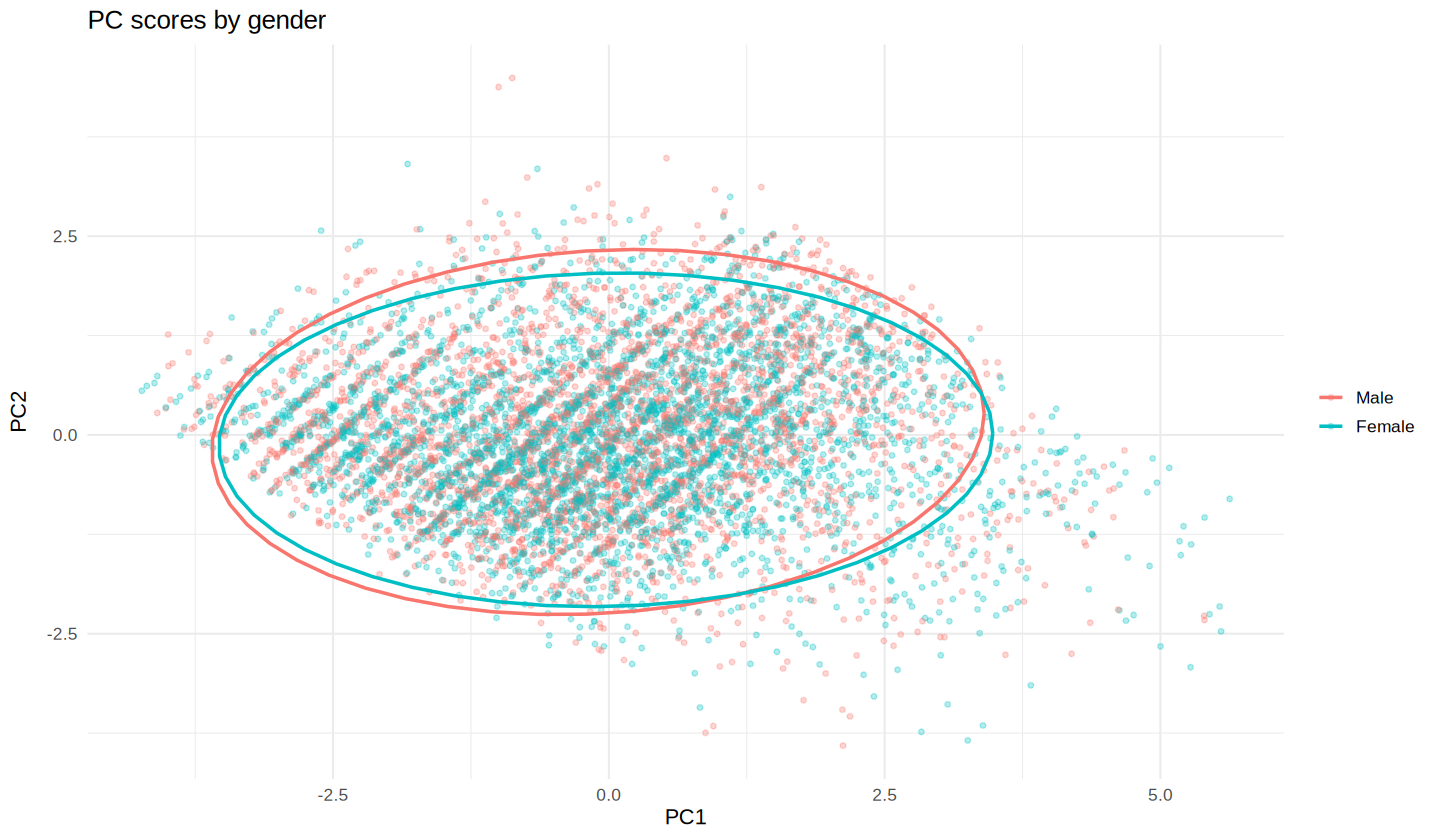

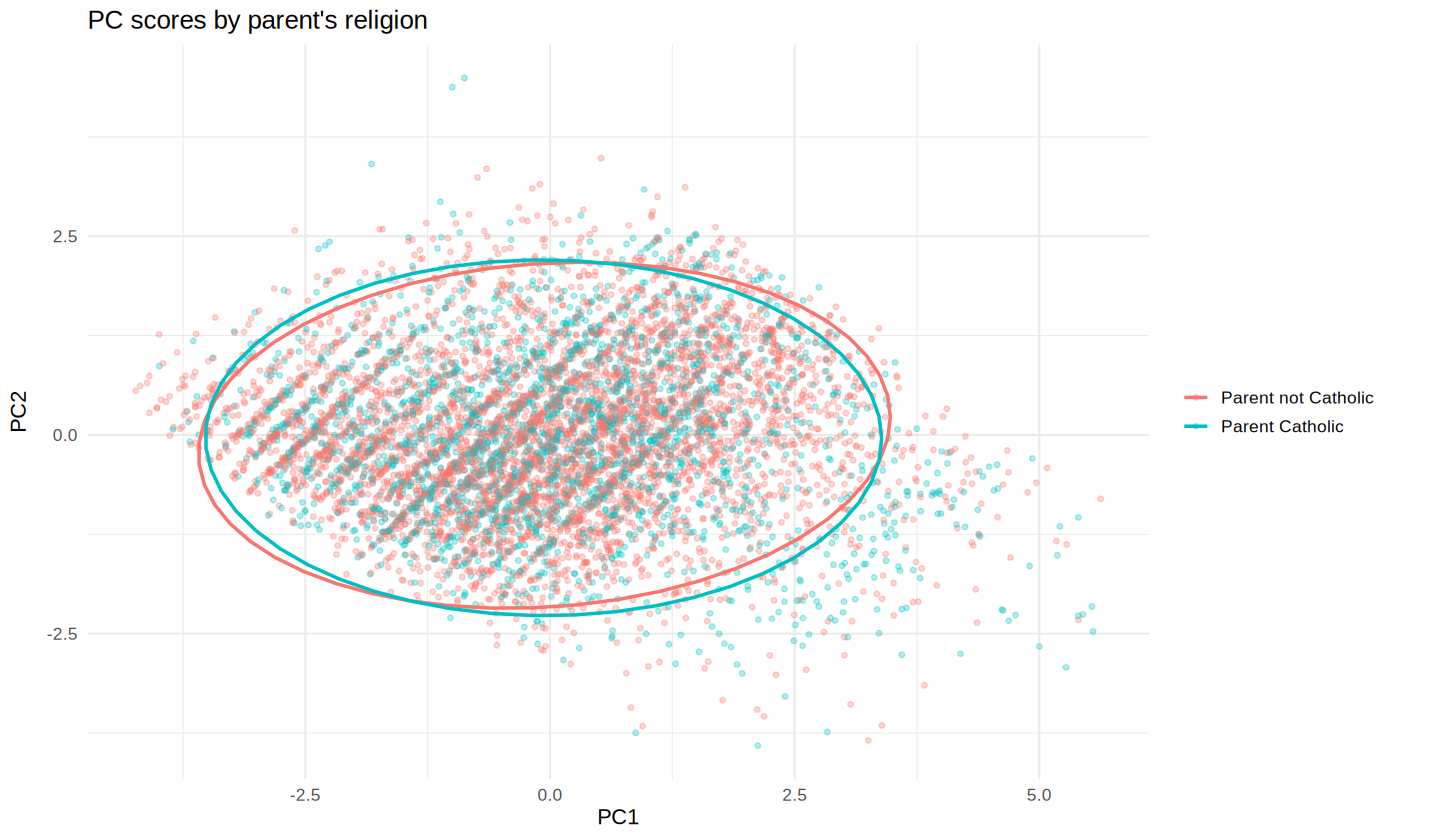

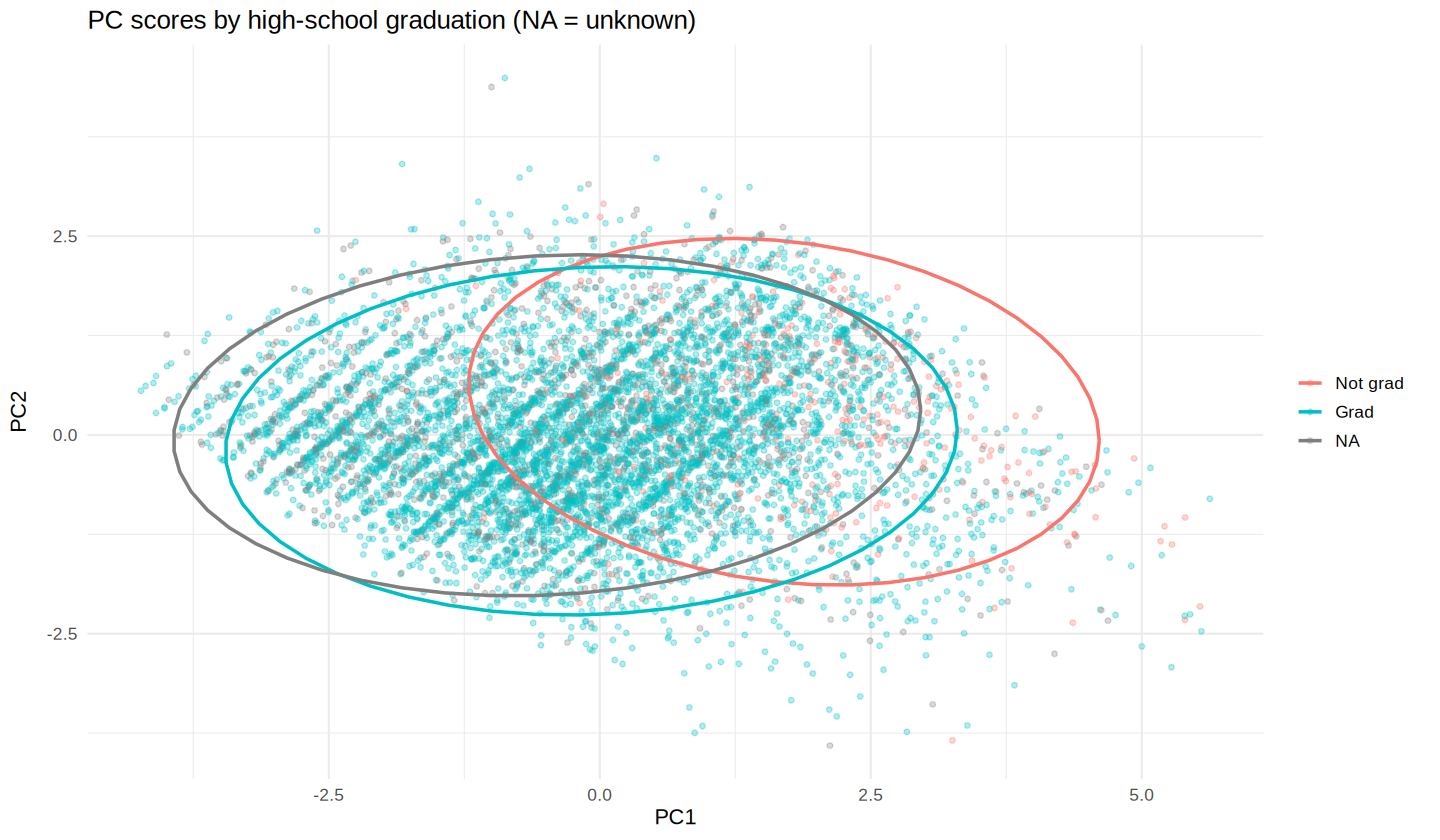

In [16]:
plot_scores <- function(group, title) {
  ggplot(df_pca, aes(PC1, PC2, colour = .data[[group]])) +
    geom_point(alpha = 0.3, size = 1.2) + stat_ellipse(linewidth = 1) +
    labs(title = title, colour = NULL) + theme_minimal(13)
}
print(plot_scores("race",     "PC scores by race"))
print(plot_scores("gender",   "PC scores by gender"))
print(plot_scores("parent",   "PC scores by parent's religion"))
print(plot_scores("hsgrad_f", "PC scores by high-school graduation (NA = unknown)"))

school,n,mean_PC1,mean_PC2
<fct>,<int>,<dbl>,<dbl>
Non-Catholic HS,6978,0.05049525,-0.005445613
Catholic HS,452,-0.77954841,0.084069665



	Welch Two Sample t-test

data:  PC1 by school
t = 12.009, df = 531.02, p-value < 0.00000000000000022
alternative hypothesis: true difference in means between group Non-Catholic HS and group Catholic HS is not equal to 0
95 percent confidence interval:
 0.6942645 0.9658228
sample estimates:
mean in group Non-Catholic HS     mean in group Catholic HS 
                   0.05049525                   -0.77954841 


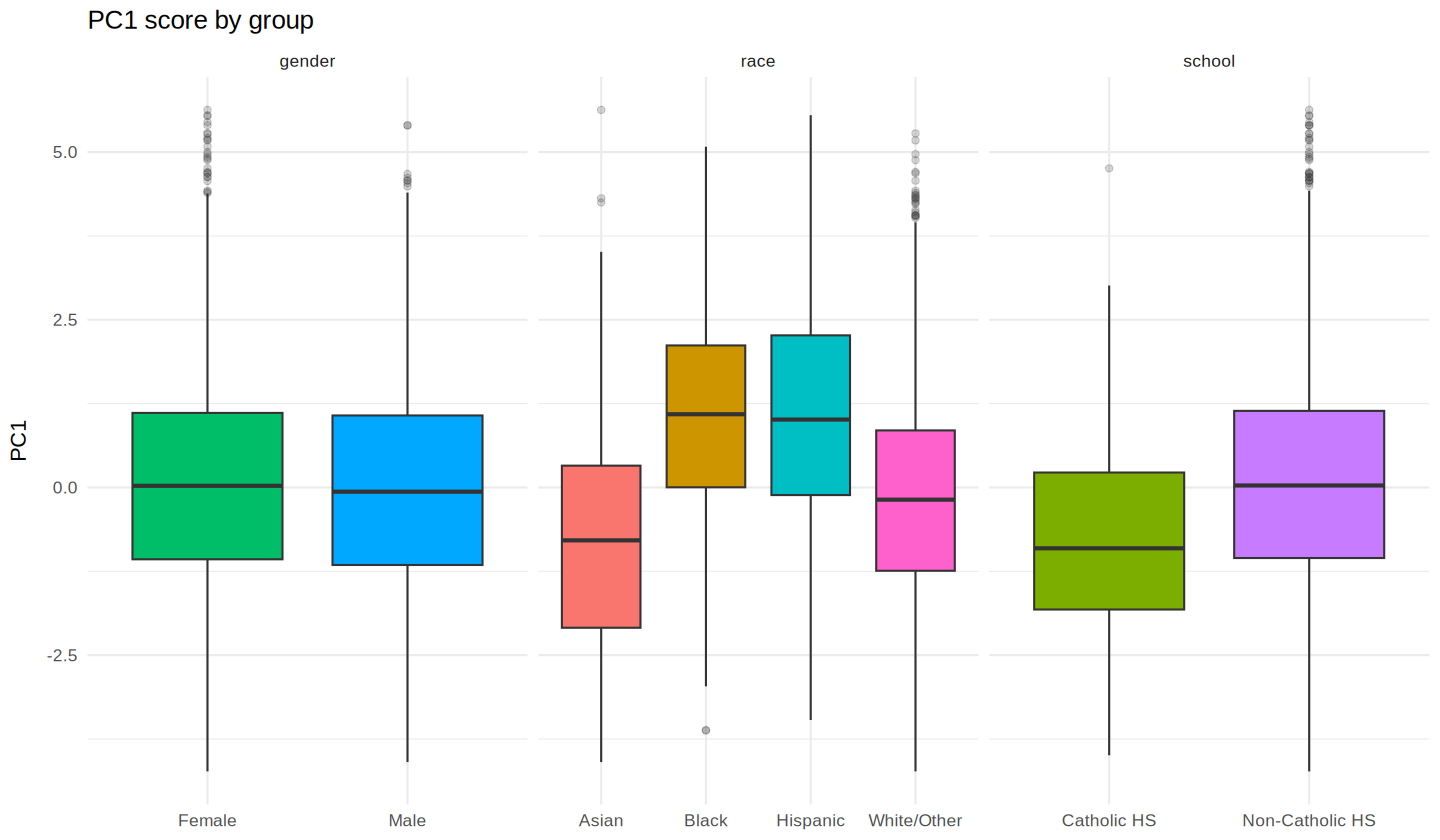

In [17]:
df_pca %>%
  pivot_longer(c(school, gender, race), names_to = "grouping", values_to = "group") %>%
  ggplot(aes(group, PC1, fill = group)) +
  geom_boxplot(show.legend = FALSE, outlier.alpha = 0.2) +
  facet_wrap(~ grouping, scales = "free_x") +
  labs(title = "PC1 score by group", x = NULL) + theme_minimal(13)

df_pca %>% group_by(school) %>%
  summarise(n = n(), mean_PC1 = mean(PC1), mean_PC2 = mean(PC2))
t.test(PC1 ~ school, data = df_pca)

In [18]:
Z     <- scale(X)
Z_hat <- pca$x[, 1:k] %*% t(pca$rotation[, 1:k])
cat("Variance kept with", k, "PCs:", round(eig$Cumulative[k], 2), "%\n")
cat("Mean squared reconstruction error (standardized units):",
    round(mean((Z - Z_hat)^2), 4), "\n")
print(round(sapply(seq_len(p), function(j) cor(Z[, j], Z_hat[, j])), 3) |>
        setNames(pca_vars))

Variance kept with 2 PCs: 73.52 %
Mean squared reconstruction error (standardized units): 0.2648 
  read12   math12 motheduc fatheduc  lfaminc 
   0.931    0.921    0.831    0.845    0.745 


I ran PCA on the five numeric columns of the Catholic school dataset (reading score, math score, mother's and father's education, and family income) after standardizing them, because they were on very different scales. Before running it, I checked whether the data was suitable: Bartlett's test was significant and the KMO was 0.70, so the variables were correlated enough for PCA to make sense. The first component explained about 52% of the variance and the second about 21%, so together they captured around 74% of the information, and only these two had eigenvalues above 1. PC1 had all five variables loading in the same direction, so I read it as an overall "academic and family advantage" score; the signs are all negative, which only means that a lower PC1 score stands for a stronger student background. PC2 split the variables into two groups, with test scores on one side and parents' education and income on the other, which tells me a student's marks and their family background don't always move together. Keeping just two components still recovered the test scores very well (about 0.93), while family income was recovered the least (about 0.75).